# Assignment 1
## Ákos Kappel

### Techniques

**Filtering**
- mean
- median
- gaussian
- bilateral

**Edge detection**
- sobel
- laplacian
- canny

**Thresholding**
- otsu
- adaptive

**Sharpening**


In [112]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [114]:
%matplotlib inline

In [115]:
class GaussianTracker:
    def __init__(self, image, ksize=0, sigmaX=0, window='image', trackbar='ksize'):
        self.img = image
        self.ksize = ksize
        self.sigmaX = sigmaX
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        blur = cv.GaussianBlur(self.img, (self.ksize, self.ksize), self.sigmaX)
        cv.imshow(self.window, blur)


class MedianTracker:
    def __init__(self, image, ksize=0, window='image', trackbar='ksize'):
        self.img = image
        self.ksize = ksize
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        blur = cv.medianBlur(self.img, self.ksize)
        cv.imshow(self.window, blur)


class BilateralTracker:
    def __init__(self, image, d=0, sigmaColor=0, sigmaSpace=0, window='image', trackbar='d'):
        self.img = image
        self.d = d
        self.sigmaColor = sigmaColor
        self.sigmaSpace = sigmaSpace
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.d, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.d = cv.getTrackbarPos(self.trackbar, self.window)
        blur = cv.bilateralFilter(self.img, self.d, self.sigmaColor, self.sigmaSpace)
        cv.imshow(self.window, blur)


class GlobalThresholdTracker:
    def __init__(self, image, thresh=0, maxval=255, type=cv.THRESH_BINARY, window='image', trackbar='threshold'):
        self.img = image
        self.thresh = thresh
        self.maxval = maxval
        self.type = type
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.thresh, self.maxval, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.thresh = cv.getTrackbarPos(self.trackbar, self.window)
        ret, thresh = cv.threshold(self.img, self.thresh, self.maxval, self.type)
        cv.imshow(self.window, thresh)


class AdaptiveThresholdTracker:
    def __init__(self, image, ksize=11, type=cv.ADAPTIVE_THRESH_GAUSSIAN_C, window='image', trackbar='threshold'):
        self.img = image
        self.ksize = ksize
        self.type = type
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 255, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        if self.ksize < 3:
            self.ksize = 3
        adaptive = cv.adaptiveThreshold(self.img, 255, self.type, cv.THRESH_BINARY, self.ksize, 2)
        cv.imshow(self.window, adaptive)


class CannyTracker:
    def __init__(self, image, threshold1=0, threshold2=0, window='image', trackbar1='threshold1',
                 trackbar2='threshold2'):
        self.img = image
        self.threshold1 = threshold1
        self.threshold2 = threshold2
        self.window = window
        self.trackbar1 = trackbar1
        self.trackbar2 = trackbar2
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar1, self.window, self.threshold1, 255, self.update)
        cv.createTrackbar(self.trackbar2, self.window, self.threshold2, 255, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.threshold1 = cv.getTrackbarPos(self.trackbar1, self.window)
        self.threshold2 = cv.getTrackbarPos(self.trackbar2, self.window)
        if self.threshold1 > self.threshold2:
            self.threshold1, self.threshold2 = self.threshold2, self.threshold1
        canny = cv.Canny(self.img, self.threshold1, self.threshold2)
        cv.imshow(self.window, canny)

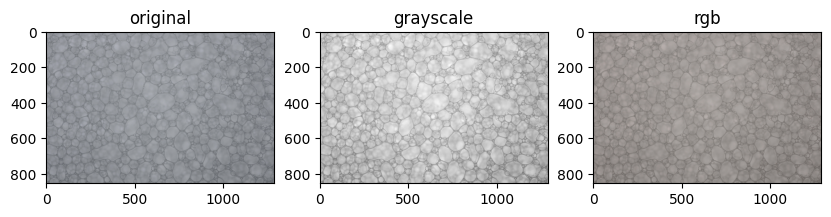

In [116]:
file1 = 'images/TCGA-18-5592-01Z-00-DX1.tif'
file2 = 'images/pena.tif'

# load image
img = cv.imread(file2)

# resize image
img = cv.resize(img, (0, 0), fx=0.3, fy=0.3)

# convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# convert to rgb
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# show images
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('original')
plt.imshow(img)
plt.subplot(1, 3, 2)
plt.title('grayscale')
plt.imshow(gray, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('rgb')
plt.imshow(rgb_img)
plt.show()

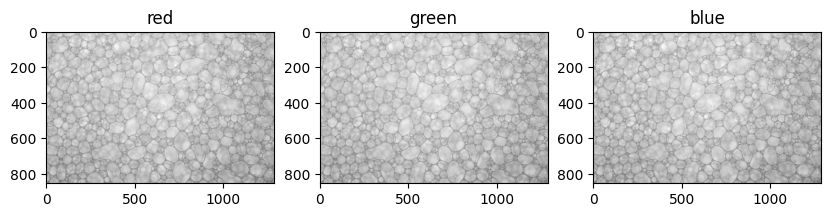

In [117]:
r, g, b = cv.split(img)

# show rgb channels in one image
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('red')
plt.imshow(r, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('green')
plt.imshow(g, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('blue')
plt.imshow(b, cmap='gray')
plt.show()

In [118]:
cv.imshow('original image', img)
cv.waitKey(0)
cv.destroyAllWindows()

In [119]:
GlobalThresholdTracker(r, window='red')
GlobalThresholdTracker(g, window='green')
GlobalThresholdTracker(b, window='blue')

In [120]:
GlobalThresholdTracker(gray)

In [121]:
GaussianTracker(img)

In [122]:
MedianTracker(img)

In [123]:
BilateralTracker(img)

In [124]:
AdaptiveThresholdTracker(gray)

In [125]:
blurred = cv.GaussianBlur(gray, (5, 5), 0)
CannyTracker(blurred)

In [126]:
# Adaptive Thresholding
blurred = cv.GaussianBlur(gray, (5, 5), 0)
adaptive = cv.adaptiveThreshold(blurred, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 7, 2)
kernel = np.ones((3, 3), np.uint8)
eroded = cv.erode(adaptive, kernel, iterations=1)

# find contours
contours, hierarchy = cv.findContours(eroded, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
# contours = [c for c in sorted(contours, key=cv.contourArea, reverse=True) if cv.contourArea(c) > 1000]
# print([cv.contourArea(c) for c in contours[:10]])
# print([cv.contourArea(c) for c in contours[-10:]])
# contour_img = cv.drawContours(img, contours, -1, (0, 255, 0), 1)
# print('Number of contours found = ', len(contours))

# plt.imshow(contour_img, cmap='gray')

def update(x):
    global contours
    count = cv.getTrackbarPos('count', 'image')
    few_contours = [c for c in contours if cv.contourArea(c) > count]
    print('Number of contours found = ', len(few_contours))
    copy = img.copy()
    new_img = cv.drawContours(copy, few_contours, -1, (0, 255, 0), 1)
    cv.imshow('image', new_img)


cv.namedWindow('image')
cv.createTrackbar('count', 'image', 5000, 10000, update)
# update(0)
cv.waitKey(0)
cv.destroyAllWindows()

Number of contours found =  30


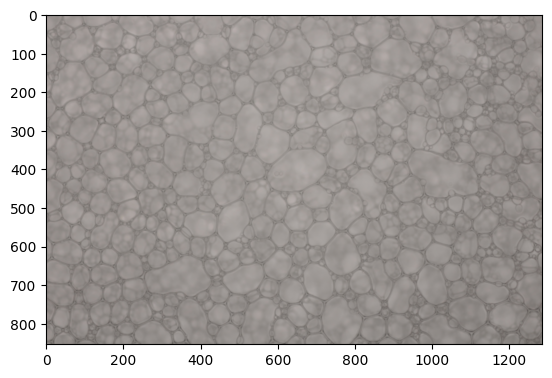

In [127]:
# gaussian blur
gaussian = cv.GaussianBlur(img, (5, 5), 0)
plt.imshow(cv.cvtColor(gaussian, cv.COLOR_BGR2RGB))
cv.imshow('gaussian', gaussian)
cv.waitKey(0)
cv.destroyAllWindows()

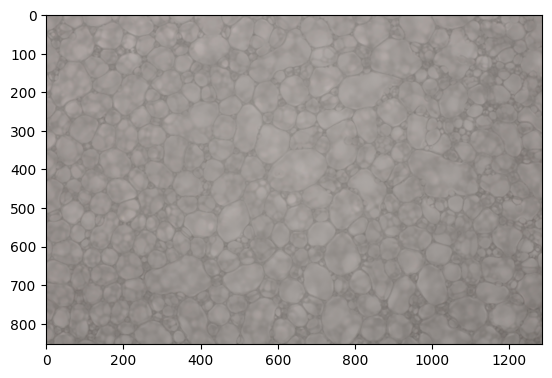

In [134]:
# median blur
median = cv.medianBlur(img, 5)
plt.imshow(cv.cvtColor(median, cv.COLOR_BGR2RGB))
cv.imshow('median', median)
cv.waitKey(0)
cv.destroyAllWindows()

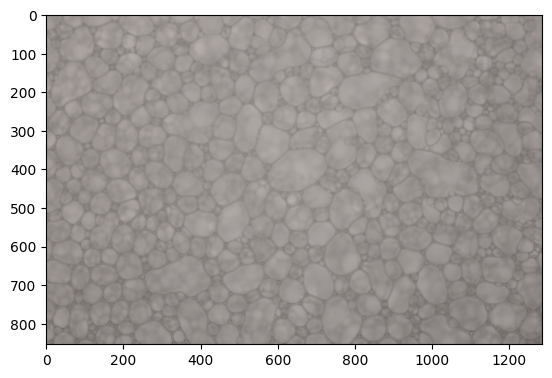

In [135]:
# bilateral blur
bilateral = cv.bilateralFilter(img, 9, 75, 75)
plt.imshow(cv.cvtColor(bilateral, cv.COLOR_BGR2RGB))
cv.imshow('bilateral', bilateral)
cv.waitKey(0)
cv.destroyAllWindows()

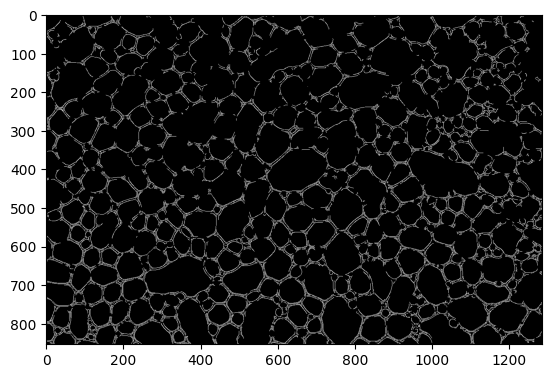

In [136]:
# canny
edges = cv.Canny(img, 100, 200)
plt.imshow(cv.cvtColor(edges, cv.COLOR_BGR2RGB))
cv.imshow('edges', edges)
cv.waitKey(0)
cv.destroyAllWindows()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


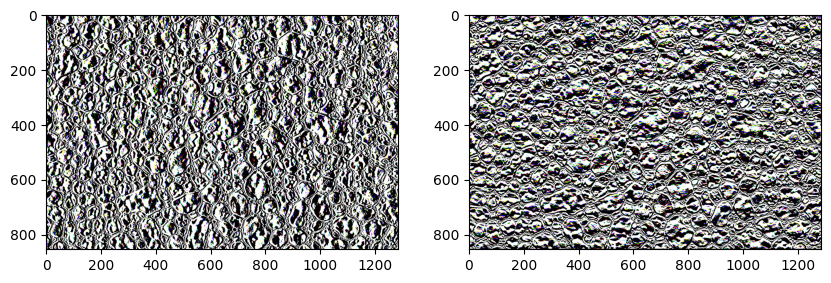

In [137]:
# sobel
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=5)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=5)
# show images next to each other
plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(sobelx)
plt.subplot(1, 2, 2)
plt.imshow(sobely)
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


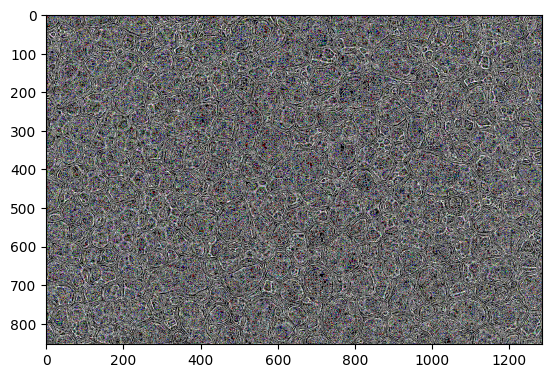

In [138]:
# laplacian
laplacian = cv.Laplacian(img, cv.CV_64F)
plt.imshow(laplacian)

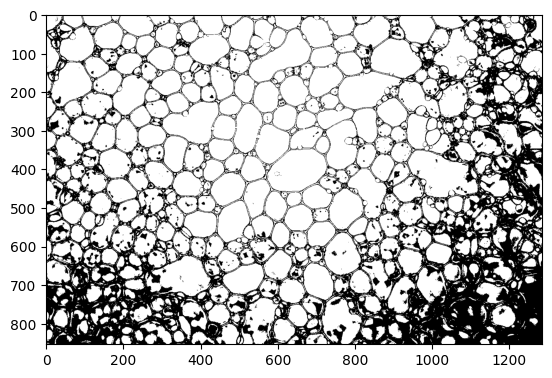

In [139]:
# thresholding
ret, thresh = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
plt.imshow(thresh, cmap='gray')